# Workshop 3 – EDA de World Happiness (2015–2019)

**Objetivo:** analizar los cinco CSV antes de armar el esquema unificado.

Estructura esperada del proyecto: los CSV van en `data/raw/` y este notebook en `notebooks/`.

## 1. Carga de los datos

In [8]:
import pandas as pd
from pathlib import Path

RAW_DIR = Path('../data/raw')
YEARS = [2015, 2016, 2017, 2018, 2019]

datasets = {year: pd.read_csv(RAW_DIR / f'{year}.csv') for year in YEARS}

for year, df in datasets.items():
    print(f'{year}: {df.shape[0]} filas, {df.shape[1]} columnas')

2015: 158 filas, 12 columnas
2016: 157 filas, 13 columnas
2017: 155 filas, 12 columnas
2018: 156 filas, 9 columnas
2019: 156 filas, 9 columnas


## 2. Estructura de cada archivo

Primero miramos las columnas de cada año para ver qué tan distintos son los esquemas.

In [9]:
for year, df in datasets.items():
    print(f'--- {year} ---')
    print(list(df.columns))
    print()

--- 2015 ---
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

--- 2016 ---
['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']

--- 2017 ---
['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']

--- 2018 ---
['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']

--- 2019 ---
['Overall rank', 'Country or region',

**Pregunta para analizar:** ¿qué columnas se repiten en todos los años (aunque con otro nombre) y cuáles no?

Bloque 4: tipos de datos

In [10]:
for year, df in datasets.items():
    print(f'--- {year} ---')
    print(df.dtypes)
    print()

--- 2015 ---
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Standard Error                   float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity                       float64
Dystopia Residual                float64
dtype: object

--- 2016 ---
Country                              str
Region                               str
Happiness Rank                     int64
Happiness Score                  float64
Lower Confidence Interval        float64
Upper Confidence Interval        float64
Economy (GDP per Capita)         float64
Family                           float64
Health (Life Expectancy)         float64
Freedom                          float64
Trust (Government Corruption)    float64
Generosity      

Bloque 5: armonizar nombres y unir (solo para explorar)

In [11]:
COLUMN_MAP = {
    'Country': 'country', 'Country or region': 'country',
    'Happiness Score': 'score', 'Happiness.Score': 'score', 'Score': 'score',
    'Economy (GDP per Capita)': 'gdp', 'Economy..GDP.per.Capita.': 'gdp', 'GDP per capita': 'gdp',
    'Family': 'family', 'Social support': 'family',
    'Health (Life Expectancy)': 'health', 'Health..Life.Expectancy.': 'health', 'Healthy life expectancy': 'health',
    'Freedom': 'freedom', 'Freedom to make life choices': 'freedom',
    'Generosity': 'generosity',
    'Trust (Government Corruption)': 'corruption', 'Trust..Government.Corruption.': 'corruption', 'Perceptions of corruption': 'corruption',
}
KEEP = ['country', 'year', 'score', 'gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']

frames = []
for year, df in datasets.items():
    tmp = df.rename(columns=COLUMN_MAP).copy()
    tmp['year'] = year
    frames.append(tmp[KEEP])

unified = pd.concat(frames, ignore_index=True)
print(unified.shape)
unified.head()

(782, 9)


,country,year,score,gdp,family,health,freedom,generosity,corruption
0,Switzerland,2015,7.587,1.39651,1.34951,0.94143,0.66557,0.29678,0.41978
1,Iceland,2015,7.561,1.30232,1.40223,0.94784,0.62877,0.43630,0.14145
2,Denmark,2015,7.527,1.32548,1.36058,0.87464,0.64938,0.34139,0.48357
3,Norway,2015,7.522,1.45900,1.33095,0.88521,0.66973,0.34699,0.36503
4,Canada,2015,7.427,1.32629,1.32261,0.90563,0.63297,0.45811,0.32957


Bloque 6: nombres de países entre años

In [12]:
paises_por_anio = {y: set(unified.loc[unified['year'] == y, 'country']) for y in YEARS}
todos = set.union(*paises_por_anio.values())
en_los_cinco = set.intersection(*paises_por_anio.values())

print('Países distintos:', len(todos))
print('Presentes en los 5 años:', len(en_los_cinco))
print()
for pais in sorted(todos - en_los_cinco):
    print(pais, '->', [y for y in YEARS if pais in paises_por_anio[y]])

Países distintos: 170
Presentes en los 5 años: 141

Angola -> [2015, 2016, 2017, 2018]
Belize -> [2016, 2017, 2018]
Central African Republic -> [2015, 2017, 2018, 2019]
Comoros -> [2015, 2016, 2019]
Djibouti -> [2015]
Gambia -> [2019]
Hong Kong -> [2015, 2016, 2018, 2019]
Hong Kong S.A.R., China -> [2017]
Laos -> [2015, 2016, 2018, 2019]
Lesotho -> [2015, 2017, 2018, 2019]
Macedonia -> [2015, 2016, 2017, 2018]
Mozambique -> [2015, 2017, 2018, 2019]
Namibia -> [2016, 2017, 2018, 2019]
North Cyprus -> [2015, 2016, 2017]
North Macedonia -> [2019]
Northern Cyprus -> [2018, 2019]
Oman -> [2015]
Puerto Rico -> [2016]
Somalia -> [2016, 2017, 2018, 2019]
Somaliland Region -> [2016]
Somaliland region -> [2015]
South Sudan -> [2016, 2017, 2018, 2019]
Sudan -> [2015, 2016, 2017, 2018]
Suriname -> [2015, 2016]
Swaziland -> [2015, 2019]
Taiwan -> [2015, 2016, 2018, 2019]
Taiwan Province of China -> [2017]
Trinidad & Tobago -> [2018, 2019]
Trinidad and Tobago -> [2015, 2016, 2017]


Bloque 7: nulos y ceros en el dataset unidos

In [13]:
cols_num = ['score', 'gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']

print('Nulos por columna:')
print(unified.isna().sum())
print()
print('Filas con algún nulo:')
display(unified[unified.isna().any(axis=1)])

print('Ceros por variable:')
print((unified[cols_num] == 0).sum())
print()
print('Filas con algún cero en las variables explicativas:')
display(unified[(unified[cols_num[1:]] == 0).any(axis=1)])

Nulos por columna:
country       0
year          0
score         0
gdp           0
family        0
health        0
freedom       0
generosity    0
corruption    1
dtype: int64

Filas con algún nulo:


,country,year,score,gdp,family,health,freedom,generosity,corruption
489,United Arab Emirates,2018,6.774,2.096,0.776,0.67,0.284,0.186,NaN


Ceros por variable:
score         0
gdp           5
family        5
health        5
freedom       5
generosity    5
corruption    6
dtype: int64

Filas con algún cero en las variables explicativas:


,country,year,score,gdp,family,health,freedom,generosity,corruption
73,Indonesia,2015,5.399,0.828270,1.087080,0.637930,0.466110,0.515350,0.000000
101,Greece,2015,4.857,1.154060,0.929330,0.882130,0.076990,0.000000,0.013970
111,Iraq,2015,4.677,0.985490,0.818890,0.602370,0.000000,0.179220,0.137880
119,Congo (Kinshasa),2015,4.517,0.000000,1.001200,0.098060,0.226050,0.248340,0.076250
122,Sierra Leone,2015,4.507,0.330240,0.955710,0.000000,0.408400,0.214880,0.087860
147,Central African Republic,2015,3.678,0.078500,0.000000,0.066990,0.488790,0.238350,0.082890
233,Somalia,2016,5.440,0.000000,0.336130,0.114660,0.567780,0.272250,0.311800
244,Bosnia and Herzegovina,2016,5.163,0.933830,0.643670,0.707660,0.095110,0.298890,0.000000
256,Greece,2016,5.033,1.248860,0.754730,0.800290,0.058220,0.000000,0.041270
268,Sierra Leone,2016,4.635,0.364850,0.628000,0.000000,0.306850,0.238970,0.081960


Bloque 8: valores atípicos (criterio IQR)

In [14]:
resumen = []
for c in cols_num:
    q1, q3 = unified[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    mask = (unified[c] < q1 - 1.5 * iqr) | (unified[c] > q3 + 1.5 * iqr)
    resumen.append({'variable': c, 'outliers': int(mask.sum()),
                    'min': unified[c].min(), 'max': unified[c].max()})

pd.DataFrame(resumen)

,variable,outliers,min,max
0,score,0,2.693,7.769000
1,gdp,0,0.000,2.096000
2,family,10,0.000,1.644000
3,health,0,0.000,1.141000
4,freedom,0,0.000,0.724000
5,generosity,17,0.000,0.838075
6,corruption,67,0.000,0.551910


Bloque 9: estadísticas descriptivas  

In [15]:
display(unified[cols_num].describe().round(3))
display(unified.groupby('year')[cols_num].mean().round(3))

,score,gdp,family,health,freedom,generosity,corruption
count,782.000,782.000,782.000,782.000,782.000,782.000,781.000
mean,5.379,0.916,1.078,0.612,0.411,0.219,0.125
std,1.127,0.407,0.330,0.248,0.153,0.122,0.106
min,2.693,0.000,0.000,0.000,0.000,0.000,0.000
25%,4.510,0.606,0.869,0.440,0.310,0.130,0.054
50%,5.322,0.982,1.125,0.647,0.431,0.202,0.091
75%,6.190,1.236,1.327,0.808,0.531,0.279,0.156
max,7.769,2.096,1.644,1.141,0.724,0.838,0.552


,score,gdp,family,health,freedom,generosity,corruption
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.237,0.143
2016,5.382,0.954,0.794,0.558,0.371,0.243,0.138
2017,5.354,0.985,1.189,0.551,0.409,0.247,0.123
2018,5.376,0.891,1.213,0.597,0.455,0.181,0.112
2019,5.407,0.905,1.209,0.725,0.393,0.185,0.111


## 3. Observaciones de calidad de datos

- **Esquemas distintos:** 2015 y 2016 traen `Region` y medidas de incertidumbre; 2017 usa nombres con puntos; 2018 y 2019 usan otro nombre para casi todas las columnas.
- **Nombres inconsistentes:** las mismas variables se llaman distinto según el año (por ejemplo, `Family` y `Social support`).
- **Tipos de datos:** todas las variables numéricas son `float64`; no hay inconsistencias de tipo.
- **Nulos:** un solo nulo, `corruption` de United Arab Emirates en 2018.
- **Duplicados:** ninguno en los cinco archivos.
- **Países:** 170 nombres distintos antes de normalizar; 6 pares eran el mismo país escrito de forma diferente. Quedan 164 países.
- **Ceros:** 30 filas con un cero en una variable. Se repiten por país entre años, por lo que se interpretan como mínimos reales de la escala.
- **Atípicos (IQR):** `corruption` (67), `generosity` (17), `family` (10). Se conservan por ser datos reales.
- **Cambios entre años:** las medias de `family` y `health` cambian bastante entre algunos años; no se usa `year` como variable del modelo.

## 4. Propuesta de esquema unificado

| Columna | Tipo | Descripción |
|---|---|---|
| country | string | Nombre normalizado del país |
| year | int | Año del informe (2015–2019) |
| score | float | Puntaje de felicidad (variable objetivo) |
| gdp | float | PIB per cápita |
| family | float | Apoyo social / familia |
| health | float | Esperanza de vida saludable |
| freedom | float | Libertad para tomar decisiones |
| generosity | float | Generosidad |
| corruption | float | Percepción de corrupción |

**Columnas descartadas:** `Region`, rangos, `Standard Error`, intervalos de confianza, `Whisker` y `Dystopia Residual` (no están en todos los años; esta última además es casi una fuga de información).

### Conclusiones de la exploración
- `gdp` (0.79), `health` (0.74) y `family` (0.65) son las variables más asociadas al puntaje; `generosity` (0.14) es la más débil.
- `gdp` y `health` están muy correlacionadas entre sí (0.79); no afecta la capacidad de predicción de un modelo simple.
- `corruption` muestra una relación no lineal: la mayoría de los países tiene valores bajos.
- Se usarán las seis variables, que coinciden con el contrato de eventos. No se usan `country`, `year`, rangos ni `Dystopia Residual` (evita fuga de información).

--------------------------------------------------------------

--------------------------------------------------------------
--------------------------------------------------------------
--------------------------------------------------------------
--------------------------------------------------------------

In [2]:
import pandas as pd

clean = pd.read_csv('../data/processed/happiness_unified.csv')
print(clean.shape)
clean.head()

(781, 9)


,country,year,score,gdp,family,health,freedom,generosity,corruption
0,Afghanistan,2015,3.575,0.31982,0.30285,0.30335,0.23414,0.36510,0.09719
1,Albania,2015,4.959,0.87867,0.80434,0.81325,0.35733,0.14272,0.06413
2,Algeria,2015,5.605,0.93929,1.07772,0.61766,0.28579,0.07822,0.17383
3,Angola,2015,4.033,0.75778,0.86040,0.16683,0.10384,0.12344,0.07122
4,Argentina,2015,6.574,1.05351,1.24823,0.78723,0.44974,0.11451,0.08484


## 6. Relación entre variables y el puntaje de felicidad

In [18]:
import matplotlib.pyplot as plt

features = ['gdp', 'family', 'health', 'freedom', 'generosity', 'corruption']

corr = clean[['score'] + features].corr().round(3)

print('Correlación de cada variable con score:')
print(corr['score'].drop('score').sort_values(ascending=False))

Correlación de cada variable con score:
gdp           0.790
health        0.743
family        0.651
freedom       0.553
corruption    0.398
generosity    0.138
Name: score, dtype: float64


Celda de código 2: mapa de calor de correlaciones

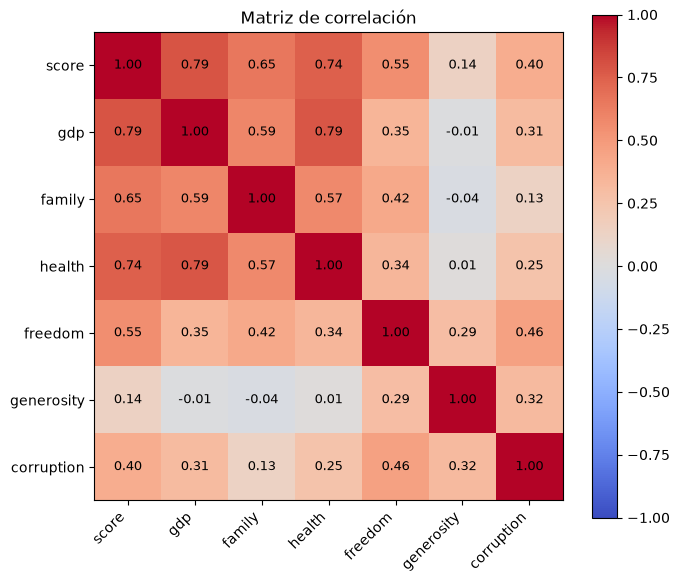

In [19]:
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)

ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)

for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)

fig.colorbar(im)
ax.set_title('Matriz de correlación')
plt.tight_layout()
plt.show()

Celda de código 3: dispersión de cada variable contra el puntaje

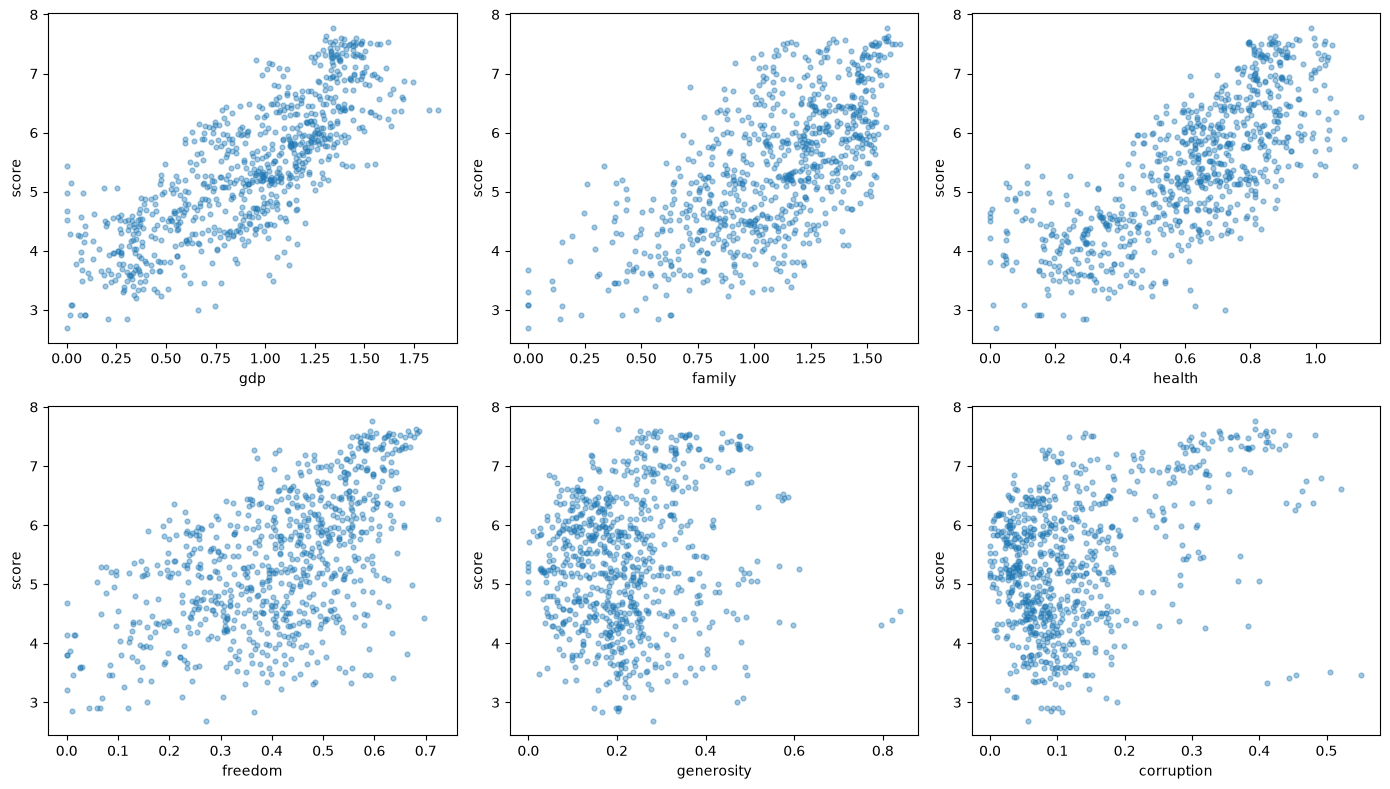

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, f in zip(axes.ravel(), features):
    ax.scatter(clean[f], clean['score'], alpha=0.4, s=12)
    ax.set_xlabel(f)
    ax.set_ylabel('score')

plt.tight_layout()
plt.show()